# PandExo noise calculator

JWST noise for one target with PandExo. The result is the precision of a band's transit (or occultation) depth. It is then converted to the noise per minute of light curve, σ_1min, which is the noise level the bias fits use.

1. Setup
2. Target
3. MIRI/LRS
4. NIRSpec: G395M vs G395H
5. From depth precision to σ_1min
6. Using the `HItargets_utils` PandExo functions

## 1. Setup
PandExo needs the Pandeia reference data and the CDBS stellar models. Both environment variables must point to existing folders.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import pandexo.engine.justdoit as jdi   # not called directly (run_pandexo imports it), but fails here if PandExo is missing
from HItargets_utils import *

In [2]:
for var in ("pandeia_refdata", "PYSYN_CDBS"):
    path = os.environ.get(var)
    print(f"{var:16s} {'ok     ' if path and os.path.isdir(path) else 'MISSING'} {os.path.basename(path.rstrip('/')) if path else '(not set)'}")   # the folder name only

pandeia_refdata  ok      pandeia_data-2026.7-jwst
PYSYN_CDBS       ok      trds


In [3]:
def plot_depth_precision(result, bins, ax):
    """Per-pixel transit-depth precision of a PandExo result (grey) and the white-light precision of each bin (orange); bins = [(l1, l2, sigma_ppm), ...] in um."""
    spec = result["FinalSpectrum"]
    ax.plot(spec["wave"], 1e6 * np.asarray(spec["error_w_floor"]), ".", color="0.6", ms=3, label="per pixel")
    for i, (l1, l2, sigma) in enumerate(bins):
        ax.hlines(sigma, l1, l2, color="C1", lw=2.5, label="per bin (white light)" if i == 0 else None)
    ax.set(yscale="log", xlabel="wavelength [µm]", ylabel="transit depth precision [ppm]")
    ax.legend()

## 2. Target
PandExo's inputs come from the archive table (`pandexo_params`). T14 is passed explicitly from `PlanetParams`, the value the pipeline uses. That value includes the `CUSTOM` / `OVERRIDES` corrections, e.g. the transit duration of TOI-2431 b, computed from its published geometry instead of the archive value.

In [4]:
name = "K2-141 b"   # e.g. "TOI-2431 b"
planet = hi_planets_by_name(name)
T14 = planet.T14   # transit duration [h]
tag = name.lower().replace(" ", "").replace("-", "")   # figure-name suffix

print(f"{planet.name}: T14 = {T14:.4g} h (archive pl_trandur: {pandexo_params(name)['t14_h']:.4g} h)")

K2-141 b: T14 = 0.94 h (archive pl_trandur: 0.94 h)


## 3. MIRI/LRS
`run_pandexo` takes an instrument key of `FILTER_LAMBDA_UM` and looks up its PandExo mode. It prints every input with its source, and PandExo's warnings.

In [5]:
instrument = "MIRI/LRS"
result_lrs = run_pandexo(name, instrument, t14_h=T14)

PandExo inputs for K2-141 b  [instrument=MIRI/LRS (PandExo: MIRI LRS)]
    period     = 0.28032      d                <- pl_orbper
    rp_rearth  = 1.51         R_earth          <- pl_rade
    rs_rsun    = 0.681        R_sun            <- st_rad
    teff       = 4570         K                <- st_teff
    logg       = 4.62         log cgs          <- st_logg
    metal      = 0            log Fe/H         <- st_met
    t14_h      = 0.94         h                <- override
    mag        = 8.401        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All good', 'Group Number 

In [6]:
pd.Series(result_lrs["timing"], name=instrument)

Transit Duration                              0.940000
Seconds per Frame                             0.156160
Time/Integration incl reset (sec)             4.372480
Measurement Time per Integration (sec)        4.060160
APT: Num Groups per Integration              27.000000
Num Integrations Out of Transit             774.000000
Num Integrations In Transit                 774.000000
Num Superstripes                              1.000000
Effective Integrations Out of Transit       774.000000
Effective Integrations In Transit           774.000000
On Source Time Out of Transit              3142.563840
On Source Time In Transit                  3142.563840
Effective On Source Time Out of Transit    3142.563840
Effective On Source Time In Transit        3142.563840
APT: Num Integrations per Occultation      1548.000000
Observing Efficiency (%)                     92.857143
Transit+Baseline, no overhead (hrs)           1.880166
Number of Transits                            1.000000
Zero Frame

The **cadence** is the duration of one integration, including the detector reset.

In [7]:
t_int = result_lrs["timing"]["Time/Integration incl reset (sec)"]
print(f"{t_int:.3f} s per integration, {result_lrs['timing']['APT: Num Groups per Integration']} groups")

4.372 s per integration, 27 groups


### Depth precision in wavelength bins
`binning(l1, l2, result)` sums the electrons of all pixels in [l1, l2] µm and returns the precision of that band's white-light transit (or occultation) depth, in ppm per transit. Here: 12 bins of 0.609 µm from 5.06 to 12.37 µm.

In [8]:
edges = 5.06 + 0.609 * np.arange(13)
bins_lrs = [(l1, l2, binning(l1, l2, result_lrs, visualize=False)) for l1, l2 in zip(edges[:-1], edges[1:])]
for l1, l2, sigma in bins_lrs:
    print(f"{l1:6.3f}-{l2:6.3f} µm: {sigma:7.2f} ppm per transit")

 5.060- 5.669 µm:   41.01 ppm per transit
 5.669- 6.278 µm:   42.53 ppm per transit
 6.278- 6.887 µm:   45.87 ppm per transit
 6.887- 7.496 µm:   50.63 ppm per transit
 7.496- 8.105 µm:   56.58 ppm per transit
 8.105- 8.714 µm:   65.84 ppm per transit
 8.714- 9.323 µm:   74.38 ppm per transit
 9.323- 9.932 µm:   89.13 ppm per transit
 9.932-10.541 µm:  118.90 ppm per transit
10.541-11.150 µm:  187.70 ppm per transit
11.150-11.759 µm:  301.92 ppm per transit
11.759-12.368 µm:  554.76 ppm per transit


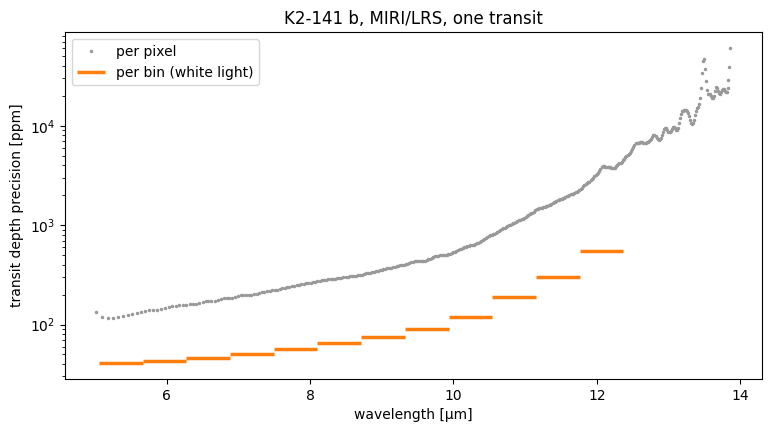

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_depth_precision(result_lrs, bins_lrs, ax)
ax.set_title(f"{name}, MIRI/LRS, one transit")
plt.show()

The throughput drops at the red end, so the pipeline trims LRS to `filter_lambda("MIRI/LRS")`. One visit in that band, and two (÷√2):

In [10]:
l1, l2 = 1e6 * filter_lambda(instrument)   # [um]
sigma_lrs = binning(l1, l2, result_lrs, visualize=False)
print(f"{instrument} {l1:g}-{l2:g} µm: {sigma_lrs:.2f} ppm from one visit, {sigma_lrs / np.sqrt(2):.2f} ppm from two")
print(f"noise per minute (section 5): σ_1min = {rms_1min_pandexo(result_lrs, T14, filter_lambda(instrument)):.2f} ppm/min")

MIRI/LRS 5-10.5 µm: 18.69 ppm from one visit, 13.22 ppm from two
noise per minute (section 5): σ_1min = 99.25 ppm/min


## 4. NIRSpec: G395M vs G395H
### G395M
G395M is not one of the pipeline's instruments, so its PandExo mode is registered here, for this notebook only.

In [11]:
PANDEXO_MODES["NIRSpec G395M"] = "NIRSpec G395M"   # notebook only, not added to FILTER_LAMBDA_UM
instrument = "NIRSpec G395M"
result_g395m = run_pandexo(name, instrument, t14_h=T14)

PandExo inputs for K2-141 b  [instrument=NIRSpec G395M (PandExo: NIRSpec G395M)]
    period     = 0.28032      d                <- pl_orbper
    rp_rearth  = 1.51         R_earth          <- pl_rade
    rs_rsun    = 0.681        R_sun            <- st_rad
    teff       = 4570         K                <- st_teff
    logg       = 4.62         log cgs          <- st_logg
    metal      = 0            log Fe/H         <- st_met
    t14_h      = 0.94         h                <- override
    mag        = 8.401        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All good', 'Gro

**Check the groups per integration.** `ngroup = 'optimize'` takes the most groups that stay below 60 % full well. A bright host fills G395M's pixels within a few groups, and PandExo warns when there are too few. Aim for at least ~5. G395H spreads the light over more pixels and so allows more groups.

In [12]:
print(f"G395M: {result_g395m['timing']['APT: Num Groups per Integration']} groups per integration")

G395M: 4 groups per integration


### G395H
One PandExo mode covers both G395H detectors. The pipeline treats NRS1 and NRS2 as separate bands.

In [13]:
instrument = "JWST_NIRSpec.G395H_NRS1"   # either array key gives the same PandExo run ("NIRSpec G395H")
result_g395h = run_pandexo(name, instrument, t14_h=T14)

PandExo inputs for K2-141 b  [instrument=JWST_NIRSpec.G395H_NRS1 (PandExo: NIRSpec G395H)]
    period     = 0.28032      d                <- pl_orbper
    rp_rearth  = 1.51         R_earth          <- pl_rade
    rs_rsun    = 0.681        R_sun            <- st_rad
    teff       = 4570         K                <- st_teff
    logg       = 4.62         log cgs          <- st_logg
    metal      = 0            log Fe/H         <- st_met
    t14_h      = 0.94         h                <- override
    mag        = 8.401        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All g

In [14]:
pd.DataFrame({"MIRI/LRS": result_lrs["timing"], "G395M": result_g395m["timing"], "G395H": result_g395h["timing"]})

,MIRI/LRS,G395M,G395H
Transit Duration,0.940000,0.940000,0.940000
Seconds per Frame,0.156160,0.902000,0.902000
Time/Integration incl reset (sec),4.372480,4.510000,10.824000
Measurement Time per Integration (sec),4.060160,2.706000,9.020000
APT: Num Groups per Integration,27.000000,4.000000,11.000000
Num Integrations Out of Transit,774.000000,751.000000,313.000000
Num Integrations In Transit,774.000000,751.000000,313.000000
Num Superstripes,1.000000,1.000000,1.000000
Effective Integrations Out of Transit,774.000000,751.000000,313.000000
Effective Integrations In Transit,774.000000,751.000000,313.000000


In [15]:
bands_g395h = {"G395H (both arrays)": (2.87, 5.17),
               "NRS1": tuple(1e6 * filter_lambda("JWST_NIRSpec.G395H_NRS1")),
               "NRS2": tuple(1e6 * filter_lambda("JWST_NIRSpec.G395H_NRS2"))}
bins_g395h = [(l1, l2, binning(l1, l2, result_g395h, visualize=False)) for l1, l2 in bands_g395h.values()]
for label, (l1, l2, sigma) in zip(bands_g395h, bins_g395h):
    print(f"{label:20s} {l1:.2f}-{l2:.2f} µm: {sigma:6.2f} ppm per transit")
print(f"{'MIRI/LRS':20s} {1e6 * filter_lambda('MIRI/LRS')[0]:.2f}-{1e6 * filter_lambda('MIRI/LRS')[1]:.2f} µm: {sigma_lrs:6.2f} ppm per transit")

G395H (both arrays)  2.87-5.17 µm:   7.74 ppm per transit
NRS1                 2.90-3.70 µm:   9.94 ppm per transit
NRS2                 3.80-5.20 µm:  12.82 ppm per transit
MIRI/LRS             5.00-10.50 µm:  18.69 ppm per transit


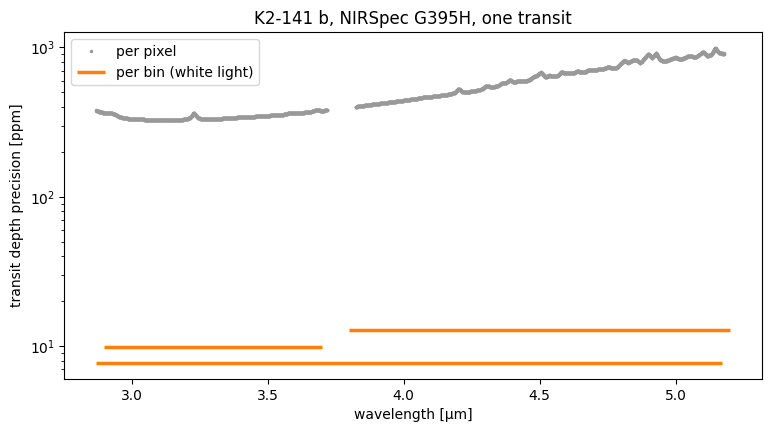

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_depth_precision(result_g395h, bins_g395h, ax)
ax.set_title(f"{name}, NIRSpec G395H, one transit")
plt.show()

Compare the depth precisions above. NIRSpec can give a smaller error than LRS, but at 3–5 µm the thermal occultation depth is also smaller than in the mid-infrared. What counts is signal over noise, so it's a trade-off.

## 5. From depth precision to σ_1min
The depth is always measured against the out-of-transit baseline. With N integrations of noise σ_int both in and out of transit:

$$\sigma_\mathrm{transit} = \sigma_\mathrm{int}\sqrt{\frac{1}{N_\mathrm{in}} + \frac{1}{N_\mathrm{out}}} = \sigma_\mathrm{int}\sqrt{\frac{2}{N}}, \qquad N = \frac{T_{14}}{t_\mathrm{int}}, \qquad \sigma_\mathrm{1min} = \sigma_\mathrm{int}\sqrt{\frac{t_\mathrm{int}}{60\,\mathrm{s}}}$$

Example: 1 h of data at 10 ppm and a 1 h transit give a depth precision of 10·√2 ppm. t_int cancels: σ_1min = σ_transit·√(T14 / 2 min).

This holds only for the settings `run_pandexo` fixes: `noccultations = 1`, `baseline_unit = 'frac'`, `baseline = 1` (equal time in and out of transit). `rms_1min_pandexo` does these steps. Here they are by hand, for G395H over both arrays.

In [17]:
t_int = result_g395h["timing"]["Time/Integration incl reset (sec)"]   # [s]
N = T14 * 3600 / t_int                                                # integrations in transit (= out of transit)
sigma_transit = binning(2.87, 5.17, result_g395h, visualize=False)    # [ppm per transit]
sigma_int = sigma_transit / np.sqrt(2 / N)                            # [ppm per integration]
sigma_1min = sigma_int * np.sqrt(t_int / 60)                          # [ppm per minute]

print(f"t_int = {t_int:.3f} s  ->  N = {N:.0f} integrations in transit (PandExo's own count: {result_g395h['timing']['Num Integrations In Transit']})")
print(f"σ_transit = {sigma_transit:.2f} ppm,  σ_int = {sigma_int:.1f} ppm,  σ_1min = {sigma_1min:.2f} ppm/min")
assert np.isclose(sigma_1min, rms_1min_pandexo(result_g395h, T14, 1e-6 * np.array([2.87, 5.17])))

t_int = 10.824 s  ->  N = 313 integrations in transit (PandExo's own count: 313)
σ_transit = 7.74 ppm,  σ_int = 96.7 ppm,  σ_1min = 41.09 ppm/min


## 6. Using the `HItargets_utils` PandExo functions
The pipeline calls only `rms_1min(planet, instrument)`. Its building blocks, in call order:

| function | returns |
|---|---|
| `pandexo_mode(instrument)` | PandExo mode for a `FILTER_LAMBDA_UM` key |
| `pandexo_params(name, **overrides)` | PandExo inputs from the archive table |
| `run_pandexo(name, instrument, **overrides)` | PandExo result dict (native resolution, one visit) |
| `binning(l1, l2, result)` | white-light depth precision [ppm] in l1–l2 µm (`visualize=True` for a quick plot) |
| `rms_1min_pandexo(result, T14, lambda_range)` | σ_1min [ppm/min] for a band in m (`extra=True` for intermediates) |
| `rms_1min(planet, instrument)` | all of the above for one `PlanetParams` |
| `rms_1min_pandexo_sample(names, instrument)` | `{name: σ_1min}` for a sample |

### Instruments and modes

In [18]:
for ins in instruments():
    l1, l2 = 1e6 * filter_lambda(ins)
    print(f"{ins:26s} {l1:5.1f}-{l2:5.1f} µm   PandExo mode: {PANDEXO_MODES[ins]}")

MIRI/F1280W                 11.6- 14.0 µm   PandExo mode: None
MIRI/F1500W                 13.5- 16.6 µm   PandExo mode: None
MIRI/F1800W                 16.5- 19.5 µm   PandExo mode: None
MIRI/LRS                     5.0- 10.5 µm   PandExo mode: MIRI LRS
Spitzer/IRAC2                4.0-  5.0 µm   PandExo mode: None
JWST_NIRSpec.G395H_NRS1      2.9-  3.7 µm   PandExo mode: NIRSpec G395H
JWST_NIRSpec.G395H_NRS2      3.8-  5.2 µm   PandExo mode: NIRSpec G395H


### Inputs
Any input can be overridden by keyword. A value missing from the archive raises an error that names the column.

In [19]:
pd.Series(pandexo_params(name, t14_h=T14), name=name)

period       0.280324
rp_rearth        1.51
rs_rsun         0.681
teff           4570.0
logg             4.62
metal             0.0
t14_h            0.94
name         K2-141 b
mag             8.401
ref_wave         2.22
mag_band      sy_kmag
Name: K2-141 b, dtype: object

### One planet, one band
`rms_1min` runs PandExo and bins to `filter_lambda(instrument)`, with T14 from the planet. It matches the step-by-step result.

In [20]:
print({k: round(float(v), 2) for k, v in rms_1min_pandexo(result_lrs, T14, filter_lambda("MIRI/LRS"), extra=True).items()})
sigma = rms_1min(planet, "MIRI/LRS", verbose=False)
print(f"rms_1min: {sigma:.2f} ppm/min")
assert np.isclose(sigma, rms_1min_pandexo(result_lrs, T14, filter_lambda("MIRI/LRS")))

{'Precision Transit': 18.69, 'Integration Duration': 4.37, 'RMS_1min_pandexo': 99.25}
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
rms_1min: 99.25 ppm/min


### Instruments without a PandExo mode
MIRI imaging has no PandExo mode. `rms_1min` then returns the hand-entered value from `CUSTOM_SIGMA_1MIN`, which is built with `sigma_1min_from_integration(snr_per_integration, t_int)`. With no entry it raises `NoNoiseLevelError`.

In [21]:
rms_1min(hi_planets_by_name("TOI-2431 b"), "MIRI/F1500W", verbose=True)
try:
    rms_1min(planet, "MIRI/F1500W")
except NoNoiseLevelError as err:
    print("NoNoiseLevelError:", err)

TOI-2431 b [MIRI/F1500W]: sigma_1min = 264.0 ppm/min from CUSTOM_SIGMA_1MIN (no PandExo mode)
NoNoiseLevelError: no noise level for 'K2-141 b' on 'MIRI/F1500W': PandExo has no mode for this instrument and CUSTOM_SIGMA_1MIN (HItargets_utils.py) has no entry for this planet/instrument (it has none for this planet). Add one there, or pass sigma_1min by hand.


### A sample
The values come from the PandExo cache (`PANDEXO_CACHE`, `inputs/noise/pandexo_cache.csv`) where possible; only a configuration not run before takes a few seconds per planet. Planets without any noise level are left out, with a note.

In [22]:
sample = ["K2-141 b", "TOI-2431 b"]
for ins in ("JWST_NIRSpec.G395H_NRS2", "MIRI/F1500W"):
    sigmas = rms_1min_pandexo_sample(sample, ins)   # {name: sigma_1min [ppm/min]}
    print(ins, {k: round(float(v), 1) for k, v in sigmas.items()})

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
JWST_NIRSpec.G395H_NRS2 {'K2-141 b': 68.1, 'TOI-2431 b': 49.4}
no noise level on MIRI/F1500W (no PandExo mode, no CUSTOM_SIGMA_1MIN entry) for 1 of 2 planets, left out: K2-141 b
MIRI/F1500W {'TOI-2431 b': 264.0}
